<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [OR-Tools Optimization](https://github.com/Query-farm/vgi-ortools)

Compute optimal assignments, vehicle routes, schedules, network flows and packings, or solve constraint models, with Google OR-Tools.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-ortools/blob/main/notebooks/03_selecting_is_not_packing_everything.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-ortools/blob/main/notebooks/README.md)


## 03 · Selecting items is not packing everything

**Does filling one valuable container answer how many containers all the goods need?** Six synthetic, indivisible items have integer masses in kilograms and illustrative priority scores. Knapsack chooses a subset for one container to maximize total score. Bin packing must include every item and minimizes the number of identical containers. Neither model represents geometric fitting, fragility, or safety rules; this is one-dimensional mass capacity only.

### Choose container capacity

`CAPACITY_KG` accepts integers **7–15 kg** (all items individually fit); default **10**, experiment **12**. Change it and restart/run all. Both problems use the same capacity, and all item weights and priority scores stay fixed. Priority points are authored utility weights, not prices or measured benefits.

In [1]:
CAPACITY_KG = 10

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.23":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.23"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
if type(CAPACITY_KG) is not int or not 7 <= CAPACITY_KG <= 15:
    raise ValueError("CAPACITY_KG must be an integer from 7 to 15 kg.")
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

theme()
session = connect(globals())
COLORS = {"A": "#287E69", "B": "#357B9D", "C": "#B16B39"}

SOURCE = "Source: six authored items · released OR-Tools worker v0.4.0 · integer kg / illustrative priority points"

### Connect to the released optimizer

The literal `uvx` command launches published **v0.4.0** in its own Python 3.13 environment. The notebook kernel installs the shared base package; the local environment adds `[runner]`. No local worker checkout, SDK override or direct Python optimizer is needed. First use needs Git, package and VGI extension downloads; the optimization itself is local CPU work. The shared connection uses an empty temporary SQL secret directory and disables persisted secrets.

`solver_info` records the actual OR-Tools version and JSON dialect. Source is release-pinned; transitive packages follow the release constraints, including OR-Tools 9.15. A status applies to the solver family: these examples use exact flow/knapsack and single-threaded CP-SAT, not routing-library heuristics.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ortools' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-ortools@v0.4.0 vgi-ortools');
SELECT component, version FROM ortools.main.solver_info ORDER BY component;

,component,version
0,cp_sat,9.15.6755
1,dialect,1
2,glop,9.15.6755
3,ortools,9.15.6755
4,pdlp,9.15.6755
5,worker,0.4.0


### Keep item identity separate from solver positions

SQL orders the scalar lists by a stable zero-based item index. Returned indices are joined back to labels, mass and score; we never interpret them as quantities. The generic two-dimensional `weights` argument has exactly one column here: kilograms.

In [5]:
%%sql matrices <<
CREATE TABLE items AS SELECT * FROM (VALUES
 (0,'A',3,9),(1,'B',5,8),(2,'C',2,4),(3,'D',7,10),(4,'E',1,3),(5,'F',4,7)
) AS i(item,label,mass_kg,priority_points);
SELECT to_json(list(priority_points ORDER BY item)) AS values_sql,
       to_json(list([mass_kg]::BIGINT[] ORDER BY item)) AS weights_sql,
       to_json(list(mass_kg ORDER BY item)) AS sizes_sql FROM items;

In [6]:
values_sql = str(matrices.values_sql.iloc[0])
weights_sql = str(matrices.weights_sql.iloc[0])
sizes_sql = str(matrices.sizes_sql.iloc[0])

### One container: choose the highest-value subset

`solve_knapsack` returns every item with a `chosen` flag. Materialize it before display and retain the unchosen rows. Omitting an item is a decision under the objective, not missing input data. Scores add, and every item may be selected at most once.

In [7]:
%%sql selection <<
CREATE TABLE selection_rows AS
SELECT * FROM ortools.main.solve_knapsack(item_values := {{ values_sql }}::BIGINT[],
 weights := {{ weights_sql }}::BIGINT[][],capacities := [{{ CAPACITY_KG }}]::BIGINT[]);
CREATE TABLE selection_audit AS SELECT i.*,s.chosen,s.status FROM items i JOIN selection_rows s USING(item);
SELECT * FROM selection_audit ORDER BY item;

In [8]:
display(selection)
assert len(selection) == 6 and set(selection.status) == {"OPTIMAL"}
chosen = selection.loc[selection.chosen]
chosen_mass = int(chosen.mass_kg.sum())
chosen_score = int(chosen.priority_points.sum())
prose(
    f"One **{CAPACITY_KG}-kg** container takes **{len(chosen)} of 6 items**: **{', '.join(chosen.label)}**, totaling **{chosen_mass} kg** and **{chosen_score} priority points**. The optimizer maximizes score, not selected-item count or mass utilization."
)

,item,label,mass_kg,priority_points,chosen,status
0,0,A,3,9,True,OPTIMAL
1,1,B,5,8,False,OPTIMAL
2,2,C,2,4,True,OPTIMAL
3,3,D,7,10,False,OPTIMAL
4,4,E,1,3,True,OPTIMAL
5,5,F,4,7,True,OPTIMAL


One **10-kg** container takes **4 of 6 items**: **A, C, E, F**, totaling **10 kg** and **23 priority points**. The optimizer maximizes score, not selected-item count or mass utilization.

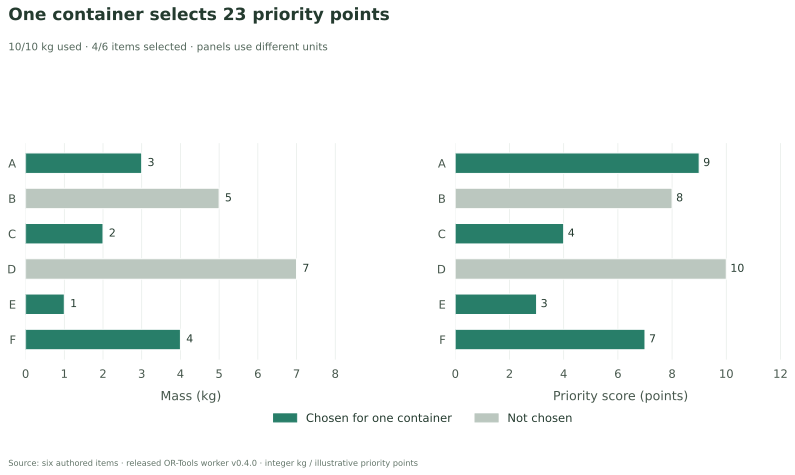

In [9]:
fig, (axw, axv) = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
y = np.arange(len(selection))
colors = ["#287E69" if c else "#BBC7BF" for c in selection.chosen]
for ax, field, unit in [
    (axw, "mass_kg", "Mass (kg)"),
    (axv, "priority_points", "Priority score (points)"),
]:
    values = selection[field].to_numpy()
    ax.barh(y, values, color=colors, height=0.58)
    for i, v in enumerate(values):
        ax.text(v + 0.15, i, str(v), va="center")
    ax.set(xlabel=unit, xlim=(0, max(values) * 1.22), yticks=y, yticklabels=selection.label)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x")
    ax.set_axisbelow(True)
axw.invert_yaxis()
axv.tick_params(labelleft=True)
fig.legend(
    handles=[
        Patch(color="#287E69", label="Chosen for one container"),
        Patch(color="#BBC7BF", label="Not chosen"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.55, 0.12),
    ncol=2,
)
finish(
    fig,
    f"One container selects {chosen_score} priority points",
    f"{chosen_mass}/{CAPACITY_KG} kg used · {len(chosen)}/6 items selected · panels use different units",
    SOURCE,
    name=f"selection-{CAPACITY_KG}",
)

### Every item: minimize the container count

`solve_bin_packing` assigns **all six items** to containers, using single-threaded CP-SAT, seed 1 and a five-second cap. A bin identifier labels an assignment; it has no physical meaning. Aggregate mass after joining the returned item IDs to the fixed input. The lower bound `ceil(total mass / capacity)` ignores indivisibility and may be unattainable on other inputs.

In [10]:
%%sql packing <<
CREATE TABLE packing_rows AS
SELECT * FROM ortools.main.solve_bin_packing(sizes := {{ sizes_sql }}::BIGINT[],
 bin_capacity := {{ CAPACITY_KG }},time_limit_s := 5.0,random_seed := 1);
CREATE TABLE packing_audit AS SELECT i.*,p.bin,p.status FROM items i JOIN packing_rows p USING(item);
SELECT * FROM packing_audit ORDER BY bin,item;

In [11]:
%%sql bin_summary <<
SELECT bin,sum(mass_kg) AS mass_kg,count(*) AS item_count,{{ CAPACITY_KG }}-sum(mass_kg) AS spare_kg
FROM packing_audit GROUP BY bin ORDER BY bin;

In [12]:
display(bin_summary)
packing_status = str(packing.status.iloc[0])
if packing_status not in {"OPTIMAL", "FEASIBLE"} or len(packing) != 6:
    raise RuntimeError("No complete feasible packing; inspect raw status rows before plotting.")
bin_count = len(bin_summary)
mass_bound = int(np.ceil(selection.mass_kg.sum() / CAPACITY_KG))
proof = "proven minimum" if packing_status == "OPTIMAL" else "best found within the cap"
prose(
    f"Packing **all 6 items ({int(selection.mass_kg.sum())} kg)** uses **{bin_count} containers**, a {proof}. The mass-only lower bound is **{mass_bound}**. This result answers a different question from the **{len(chosen)}-item** subset above; the other items cannot disappear from an all-item packing."
)

,bin,mass_kg,item_count,spare_kg
0,0,7.0,1,3.0
1,1,7.0,3,3.0
2,2,8.0,2,2.0


Packing **all 6 items (22 kg)** uses **3 containers**, a proven minimum. The mass-only lower bound is **3**. This result answers a different question from the **4-item** subset above; the other items cannot disappear from an all-item packing.

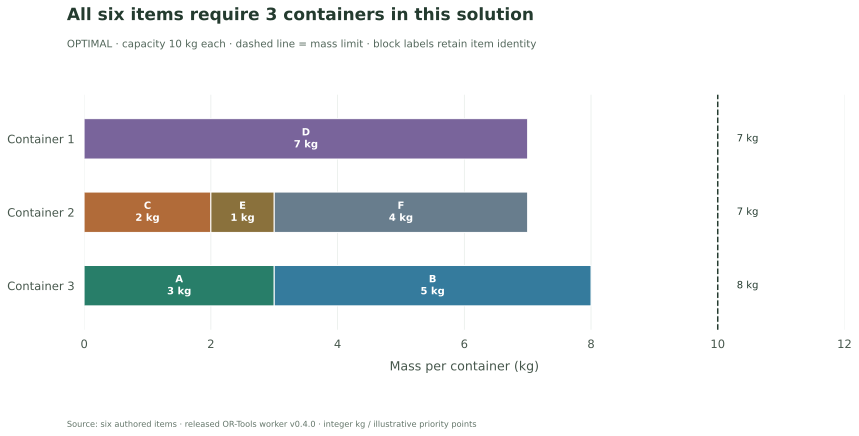

In [13]:
fig, ax = plt.subplots(figsize=(12, 6.4))
palette = ["#287E69", "#357B9D", "#B16B39", "#79649B", "#8A713C", "#687D8D"]
for y, b in enumerate(bin_summary.bin):
    left = 0
    for row in packing.loc[packing.bin == b].sort_values("item").itertuples():
        ax.barh(y, row.mass_kg, left=left, height=0.55, color=palette[row.item], edgecolor="white")
        ax.text(
            left + row.mass_kg / 2,
            y,
            f"{row.label}\n{row.mass_kg} kg",
            ha="center",
            va="center",
            color="white",
            fontsize=10,
            weight="bold",
        )
        left += row.mass_kg
    ax.text(CAPACITY_KG + 0.3, y, f"{left} kg", va="center", fontsize=10)
ax.axvline(CAPACITY_KG, color="#243B2F", ls="--", lw=1.5)
ax.set(
    yticks=np.arange(bin_count),
    yticklabels=[f"Container {int(b) + 1}" for b in bin_summary.bin],
    xlabel="Mass per container (kg)",
    xlim=(0, CAPACITY_KG + 2),
    ylim=(-0.6, bin_count - 0.4),
)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x")
ax.set_axisbelow(True)
finish(
    fig,
    f"All six items require {bin_count} containers in this solution",
    f"{packing_status} · capacity {CAPACITY_KG} kg each · dashed line = mass limit · block labels retain item identity",
    SOURCE,
    name=f"packing-{CAPACITY_KG}",
)

### Check both objectives against the fixed input

There are only 64 subsets of six items. SQL enumerates them to independently reconcile the returned knapsack score with the best feasible subset score; Python never solves the model. For bin packing, validate one assignment per original item, every container's mass, and the mass-only lower bound. A score optimum does not certify a minimum bin count, or vice versa.

In [14]:
%%sql checks <<
WITH subsets AS (
 SELECT mask,sum(CASE WHEN (mask & (1::BIGINT << item))<>0 THEN mass_kg ELSE 0 END) AS mass_kg,
 sum(CASE WHEN (mask & (1::BIGINT << item))<>0 THEN priority_points ELSE 0 END) AS score
 FROM range(64) s(mask) CROSS JOIN items GROUP BY mask
), loads AS (SELECT bin,sum(mass_kg) AS mass_kg FROM packing_audit GROUP BY bin)
SELECT 'Every selection flag returned once' AS check_name,count(*)=6 AND count(DISTINCT item)=6 AND count(chosen)=6 AS passed FROM selection_rows
UNION ALL SELECT 'Selection fits the capacity',sum(mass_kg) FILTER(WHERE chosen)<={{ CAPACITY_KG }} FROM selection_audit
UNION ALL SELECT 'Selection reaches enumerated optimum',(SELECT sum(priority_points) FROM selection_audit WHERE chosen)=max(score) FROM subsets WHERE mass_kg<={{ CAPACITY_KG }}
UNION ALL SELECT 'Every item packed once',count(*)=6 AND count(DISTINCT item)=6 AND count(bin)=6 FROM packing_rows
UNION ALL SELECT 'Every container fits',bool_and(mass_kg<={{ CAPACITY_KG }}) FROM loads
UNION ALL SELECT 'Packing preserves total mass',sum(mass_kg)=(SELECT sum(mass_kg) FROM items) FROM packing_audit
UNION ALL SELECT 'Container count respects mass bound',count(*)>=ceil((SELECT sum(mass_kg) FROM items)/{{ CAPACITY_KG }}) FROM loads;

In [15]:
display(checks)
assert checks.passed.all()
prose(
    f"All **{len(checks)} checks pass**. The one-container score matches exhaustive SQL enumeration, and the all-item allocation preserves every item and kilogram. These checks cover the authored mass model, not geometric loading or real shipment suitability."
)

,check_name,passed
0,Every selection flag returned once,True
1,Selection fits the capacity,True
2,Selection reaches enumerated optimum,True
3,Every item packed once,True
4,Every container fits,True
5,Packing preserves total mass,True
6,Container count respects mass bound,True


All **7 checks pass**. The one-container score matches exhaustive SQL enumeration, and the all-item allocation preserves every item and kilogram. These checks cover the authored mass model, not geometric loading or real shipment suitability.

### Experiment: increase each container from 10 to 12 kg

Set **`CAPACITY_KG = 12`**, restart/run all and compare both figures. Predict whether a higher optimal score requires more selected items, and whether the all-item container count falls. A higher score need not require more selected items or fill all capacity. Tied optimal subsets can also have different item counts; inspect the returned flags rather than assuming a unique selection. Reset to **10**.

The six original weights and scores must stay identical. Compare selected labels/score and all-item bin count, not raw bin IDs or incidental tie-breaking between equally optimal assignments.

In [16]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-ortools](https://github.com/Query-farm/vgi-ortools)
